# Figure 3 · Residual reconstruction and the two upsampling heads

**Question:** Which computations are shared, and what changes in the direct-5× experiment?

**Status:** implementation-verified vector draft. The historical `rrdb_blocks`
attribute contains eight **single residual dense blocks**, not nested RRDBs.
The diagram must show the legacy interpolation after the reconstruction layers.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v01'

In [2]:
FIGSIZE = (9.0, 6.0)
source = ROOT / 'code/residual_baseline.py'
provenance = ROOT / 'runs/residual-full50-s20261016/provenance.json'
verified_sources(provenance, ['residual_baseline.py'])

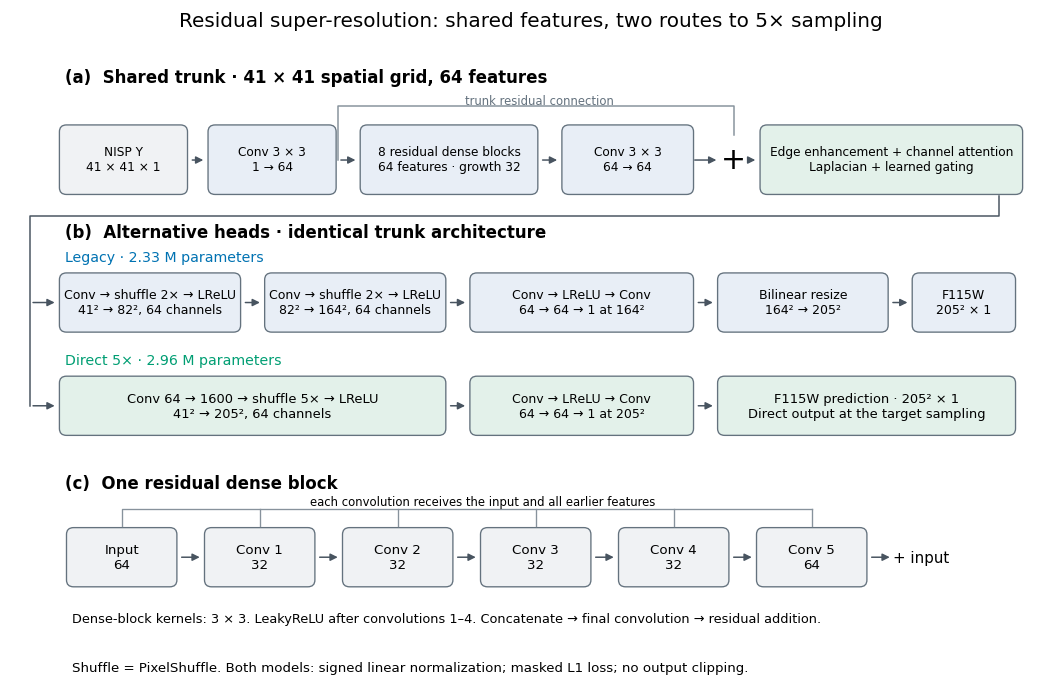

In [3]:
fig, ax = plt.subplots(figsize=FIGSIZE)
fig.subplots_adjust(left=.02, right=.98, top=.91, bottom=.04)
ax.set(xlim=(-.65, 14), ylim=(0, 9.1)); ax.axis('off')
ax.text(.1, 8.8, '(a)  Shared trunk · 41 × 41 spatial grid, 64 features', fontsize=10, fontweight='semibold')
for x, w, text, color in [(.1, 1.65, 'NISP Y\n41 × 41 × 1', '#F0F2F4'),
    (2.2, 1.65, 'Conv 3 × 3\n1 → 64', '#E8EEF6'),
    (4.35, 2.35, '8 residual dense blocks\n64 features · growth 32', '#E8EEF6'),
    (7.2, 1.7, 'Conv 3 × 3\n64 → 64', '#E8EEF6'),
    (10.0, 3.55, 'Edge enhancement + channel attention\nLaplacian + learned gating', '#E3F1EA')]:
    box(ax, x, 7.25, w, .85, text, color, 7.3)
for start, end in [(1.85, 2.1), (3.95, 4.25), (6.8, 7.1), (8.95, 9.35), (9.75, 9.9)]:
    arrow(ax, (start, 7.67), (end, 7.67))
ax.text(9.55, 7.67, '+', ha='center', va='center', fontsize=18)
ax.plot([3.95, 3.95, 9.55, 9.55], [7.67, 8.45, 8.45, 8.03], color='#87929C', lw=.9)
ax.text(6.8, 8.48, 'trunk residual connection', ha='center', fontsize=7, color='#64727E')
# Route the shared output to the two alternative head inputs.
ax.plot([13.3, 13.3, -.4, -.4], [7.15, 6.85, 6.85, 4.1], color='#485460', lw=.9)
for head_y in (5.6, 4.1):
    arrow(ax, (-.4, head_y), (0., head_y))
ax.text(.1, 6.55, '(b)  Alternative heads · identical trunk architecture', fontsize=10, fontweight='semibold')
for y, name, color in [(5.25, 'Legacy · 2.33 M parameters', '#E8EEF6'),
                        (3.75, 'Direct 5× · 2.96 M parameters', '#E3F1EA')]:
    ax.text(.1, y + .95, name, fontsize=8.5, color=COLORS['legacy'] if y > 4 else COLORS['direct5'])
    if y > 4:
        box(ax, .1, y, 2.4, .7, 'Conv → shuffle 2× → LReLU\n41² → 82², 64 channels', color, 7.5)
        box(ax, 3., y, 2.4, .7, 'Conv → shuffle 2× → LReLU\n82² → 164², 64 channels', color, 7.5)
        box(ax, 5.9, y, 3., .7, 'Conv → LReLU → Conv\n64 → 64 → 1 at 164²', color, 7.5)
        box(ax, 9.4, y, 2.25, .7, 'Bilinear resize\n164² → 205²', color, 7.5)
        box(ax, 12.15, y, 1.3, .7, 'F115W\n205² × 1', color, 7.5)
        for start, end in [(2.6, 2.9), (5.5, 5.8), (9., 9.3), (11.75, 12.05)]: arrow(ax, (start, y + .35), (end, y + .35))
    else:
        box(ax, .1, y, 5.3, .7, 'Conv 64 → 1600 → shuffle 5× → LReLU\n41² → 205², 64 channels', color, 7.8)
        box(ax, 5.9, y, 3., .7, 'Conv → LReLU → Conv\n64 → 64 → 1 at 205²', color, 7.5)
        box(ax, 9.4, y, 4.05, .7, 'F115W prediction · 205² × 1\nDirect output at the target sampling', color, 7.8)
        arrow(ax, (5.5, y + .35), (5.8, y + .35)); arrow(ax, (9., y + .35), (9.3, y + .35))
ax.text(.1, 2.9, '(c)  One residual dense block', fontsize=10, fontweight='semibold')
for i, text in enumerate(['Input\n64', 'Conv 1\n32', 'Conv 2\n32', 'Conv 3\n32', 'Conv 4\n32', 'Conv 5\n64']):
    box(ax, .2 + i * 1.95, 1.55, 1.4, .7, text, '#F0F2F4', 8)
    if i: arrow(ax, (1.7 + (i-1) * 1.95, 1.9), (.1 + i * 1.95, 1.9))
ax.plot([.9, .9, 10.65], [2.35, 2.6, 2.6], color='#87929C', lw=.8)
for i in range(1, 6):
    ax.plot([.9 + i*1.95, .9 + i*1.95], [2.6, 2.35], color='#87929C', lw=.8)
ax.text(6., 2.65, 'each convolution receives the input and all earlier features', ha='center', fontsize=7)
ax.text(12.2, 1.9, '+ input', ha='center', va='center', fontsize=9)
arrow(ax, (11.45, 1.9), (11.8, 1.9))
ax.text(.2, .95, 'Dense-block kernels: 3 × 3. LeakyReLU after convolutions 1–4. Concatenate → final convolution → residual addition.', fontsize=7.7)
ax.text(.2, .25, 'Shuffle = PixelShuffle. Both models: signed linear normalization; masked L1 loss; no output clipping.', fontsize=8)
fig.suptitle('Residual super-resolution: shared features, two routes to 5× sampling', fontsize=12)
plt.show()

In [4]:
paths = export(fig, f'fig03_residual_architecture_{VERSION}', '03_residual_architecture.ipynb',
               [source, provenance], dict(figsize=FIGSIZE, blocks=8, features=64, growth=32,
               parameters={'legacy':2332177, 'direct5':2959953}),
               status='implementation-verified vector schematic draft')

Exported: fig03_residual_architecture_v01.pdf, fig03_residual_architecture_v01.svg, fig03_residual_architecture_v01.png


## Working caption

Residual reconstruction models and the direct-5× head comparison. The shared
trunk contains eight residual dense blocks and an edge-enhancement/channel-gating
module. The legacy head applies two 2× pixel-shuffle stages, reconstruction at
164×164, and a final bilinear resize. The direct head uses one 5× pixel-shuffle
stage and reconstructs directly at 205×205. The inset describes a single dense
block, with concatenated intermediate features and a local residual addition.

## Review together

- Keep the dense-block inset, or replace it with an edge-module inset?
- The trunk is drawn once for readability; both head rows receive its output.
- Parameter counts differ: this is not a parameter-matched ablation.
- Same seed initializes the trunk identically; reconstruction-layer initial
  weights differ because the new head consumes a different random stream.
- The fork shows alternative model heads, not simultaneous outputs of one model.